# NUAA - Análise e Investigação do Dataset

## Objetivo

Analisar e invetigar informações do dataset **NUAA Photograph Imposter Database**.

### Informações a analisar

- Classe (`bona_fide` / `spoof`)
- Split (`train` / `test`)
- Sujeito
- Sessão
- Condição / posição
- Resolução das imagens
- Contagens principais

In [1]:
#read the zip files
import zipfile

#any type of io files, we use this
from io import BytesIO

#save the info in a csv file
import pandas as pd

#read the images
from PIL import Image

#display imagens
from IPython.display import display

ImportError: DLL load failed while importing internals: Uma política de Controlo de Aplicações bloqueou este ficheiro.

## 1. Localização do dataset

O dataset será lido diretamente a partir do ficheiro ZIP.

In [24]:
ZIP_PATH = "../Datasets/NUAA.zip"

## 2. Definição dos ficheiros de treino e teste

O dataset contém quatro ficheiros que identificam as imagens pertencentes aos conjuntos de treino e teste.

- `ClientFace` corresponde a `bona_fide`
- `ImposterFace` corresponde a `spoof`

In [25]:
files = {
    "client_train_face.txt":   ("bona_fide", 0, "train", "ClientFace"),
    "client_test_face.txt":    ("bona_fide", 0, "test", "ClientFace"),
    "imposter_train_face.txt": ("spoof",     1, "train", "ImposterFace"),
    "imposter_test_face.txt":  ("spoof",     1, "test",  "ImposterFace")
}

## 3. Leitura do dataset

Cada nome de imagem contém informação adicional.

Formato:

`ID_glasses_position_session_picture.jpg`

Exemplo:

`0010_01_05_03_115.jpg`

In [26]:
rows = []

with zipfile.ZipFile(ZIP_PATH) as z:

    for txt_name, (label, class_id, split, folder) in files.items():

        text = z.read(f"NUAA/{txt_name}").decode("latin1")

        for line in text.splitlines():

            relative_path = line.split()[0].replace("\\", "/")
            filename = relative_path.split("/")[-1]

            subject, glasses, position, session, picture = filename[:-4].split("_")

            rows.append({
                "filepath": f"NUAA/{folder}/{relative_path}",
                "label": label,
                "class_id": class_id,
                "split": split,
                "subject": subject,
                "glasses": glasses,
                "position": position,
                "session": session,
                "picture": picture
            })

df = pd.DataFrame(rows)

df.head()

,filepath,label,class_id,split,subject,glasses,position,session,picture
0,NUAA/ClientFace/0001/0001_00_00_01_0.jpg,bona_fide,0,train,0001,00,00,01,0
1,NUAA/ClientFace/0001/0001_00_00_01_101.jpg,bona_fide,0,train,0001,00,00,01,101
2,NUAA/ClientFace/0001/0001_00_00_01_105.jpg,bona_fide,0,train,0001,00,00,01,105
3,NUAA/ClientFace/0001/0001_00_00_01_109.jpg,bona_fide,0,train,0001,00,00,01,109
4,NUAA/ClientFace/0001/0001_00_00_01_112.jpg,bona_fide,0,train,0001,00,00,01,112


## 4. Contagens principais

Nesta secção são analisados:

- número total de imagens;
- número de imagens `bona_fide`;
- número de imagens `spoof`;
- distribuição entre treino e teste;
- número de sujeitos.

In [27]:
print("Total de imagens:", len(df))

print("\nClasses:")
print(df["label"].value_counts())

print("\nTrain / Tests:")
print(pd.crosstab(df["split"], df["label"]))

print("\n Num de sujeitos;")
print(df["subject"].nunique())

Total de imagens: 12614

Classes:
label
spoof        7509
bona_fide    5105
Name: count, dtype: int64

Train / Tests:
label  bona_fide  spoof
split                  
test        3362   5761
train       1743   1748

 Num de sujeitos;
16


## 5. Análise das sessões

In [28]:
print(pd.crosstab(df["split"], df["session"]))

session    01    02    03
split                    
test        0     0  9123
train    1744  1747     0


## 6. Análise das condições / posições

In [29]:
print("Códigos de posições encontradas:")
print(sorted(df["position"].unique()))

print("\nNúmero de imagens por posição:")
print(df["position"].value_counts().sort_index())

Códigos de posições encontradas:
['00', '01', '02', '03', '04', '05', '06', '07', '08']

Número de imagens por posição:
position
00    2598
01    1439
02    1245
03    1390
04    1376
05     624
06    1422
07    1316
08    1204
Name: count, dtype: int64


## 7. Verificar sujeitos em treino e teste

Esta análise permite verificar se existem sujeitos presentes simultaneamente nos conjuntos de treino e teste.

In [30]:
train_subjects = set(df[df["split"] == "train"]["subject"])
test_subjects = set(df[df["split"] == "test"]["subject"])

common_subjects = sorted(train_subjects & test_subjects)

print("Sujeitos no treino:", len(train_subjects))
print("Sujeitos no teste:", len(test_subjects))
print("Sujeitos presentes nos dois:", common_subjects)

Sujeitos no treino: 9
Sujeitos no teste: 16
Sujeitos presentes nos dois: ['0001', '0002', '0003', '0004', '0005', '0006', '0007', '0008', '0009']


## 8. Resolução das imagens

As dimensões de cada imagem são obtidas diretamente dos ficheiros presentes no ZIP.

In [31]:
sizes = []

with zipfile.ZipFile(ZIP_PATH) as z:
    for path in df["filepath"]:
        image_data = z.read(path)
        with Image.open(BytesIO(image_data)) as img:
            sizes.append(img.size)

df[["width", "height"]] = sizes

df[["width", "height"]].value_counts()

width  height
162    162       4830
203    203       3871
252    252       1791
131    131       1294
317    317        414
103    103        396
393    393         18
Name: count, dtype: int64

## 9. Visualização de exemplos

São apresentadas algumas imagens `bona_fide` e `spoof`.

bona_fide | Sujeito: 0011 | Sessão: 03


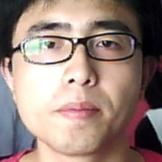

bona_fide | Sujeito: 0014 | Sessão: 03


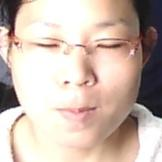

spoof | Sujeito: 0005 | Sessão: 03


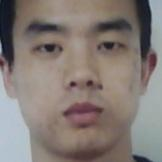

spoof | Sujeito: 0011 | Sessão: 03


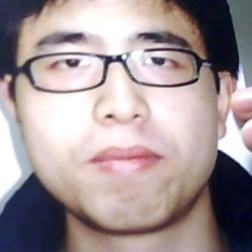

In [32]:
with zipfile.ZipFile(ZIP_PATH) as z:
    samples = df.groupby("label").sample(2, random_state=1)
    for _,row in samples.iterrows():
        image_data = z.read(row["filepath"])
        img = Image.open(BytesIO(image_data)).convert("RGB")

        print(
            row["label"],
            "| Sujeito:", row["subject"],
            "| Sessão:", row["session"]
        )

        display(img)

## 10. Resumo do dataset

In [33]:
summary = pd.DataFrame({
    "Parametro": [
        "Total de imagens",
        "Bona fide",
        "Spoof",
        "Imagens de treino",
        "Imagens de teste",
        "Sujeitos",
        "Sessões",
        "Posições / condições",
        "Resoluções diferentes"
    ],
    "Valor": [
        len(df),
        (df["label"] == "bona_fide").sum(),
        (df["label"] == "spoof").sum(),
        (df["split"] == "train").sum(),
        (df["split"] == "test").sum(),
        df["subject"].nunique(),
        df["session"].nunique(),
        df["position"].nunique(),
        len(df[["width", "height"]].drop_duplicates())
    ]
})

summary

,Parametro,Valor
0,Total de imagens,12614
1,Bona fide,5105
2,Spoof,7509
3,Imagens de treino,3491
4,Imagens de teste,9123
5,Sujeitos,16
6,Sessões,3
7,Posições / condições,9
8,Resoluções diferentes,7


## 11. Exportação dos resultados

O `DataFrame` final é guardado em CSV para poder ser usado mais tarde na análise e no treino dos modelos.

In [35]:
df.to_csv("results_datasets/nuaa_dataset_report.csv", index=False)

print("Ficheiro criado: nuaa_dataset_report.csv")

Ficheiro criado: nuaa_dataset_report.csv


## Conclusão

A versão analisada do NUAA contém **12 614 imagens**, das quais **5 105**
correspondem a apresentações `bona_fide` e **7 509** a apresentações `spoof`.

O dataset encontra-se dividido em treino e teste. Foram identificadas três
sessões de aquisição, sendo as sessões 1 e 2 utilizadas no conjunto de treino
e a sessão 3 no conjunto de teste. Esta divisão permite introduzir alguma
variação das condições de aquisição entre treino e teste.

As imagens apresentam diferentes resoluções, apesar de nesta versão já
corresponderem a faces previamente detetadas e recortadas.

O NUAA é um dataset relativamente simples e é principalmente orientado para
ataques baseados em fotografias. Não apresenta a diversidade de ataques,
sensores e dispositivos necessária para ser utilizado isoladamente como
benchmark principal desta dissertação.

No entanto, a sua estrutura simples torna-o adequado para validar inicialmente
a pipeline de carregamento, pré-processamento e classificação
`bona_fide` vs. `spoof`, podendo também ser utilizado como dataset auxiliar
em experiências de generalização.